In [1]:
import pandas as pd
from matplotlib import pyplot as plt

df = pd.read_csv("monthly-car-sales.csv")
print(df)


       Month  Sales
0    1960-01   6550
1    1960-02   8728
2    1960-03  12026
3    1960-04  14395
4    1960-05  14587
..       ...    ...
103  1968-08  16722
104  1968-09  14385
105  1968-10  21342
106  1968-11  17180
107  1968-12  14577

[108 rows x 2 columns]


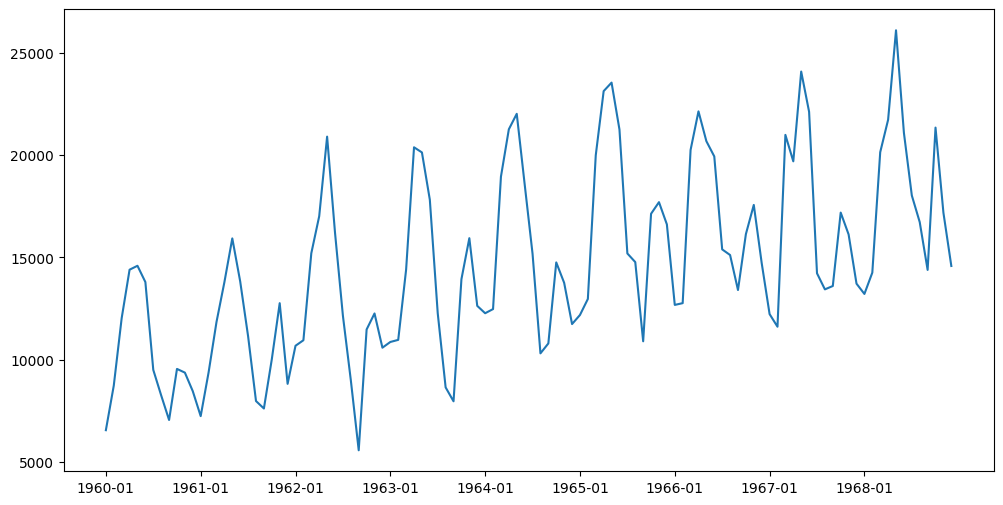

In [2]:
plt.figure(figsize=(12,6))
plt.plot(df.Month,df.Sales)
plt.xticks(df.Month[::12])
plt.show()

In [3]:
#Training set: 1960-01 to 1967-12
#Test set: 1968-01 to 1968-12

df.columns = ['ds','y']
df_data_train = df[df["ds"] < "1968-01"]
df_data_test = df[df["ds"] >= "1968-01"]

In [6]:
##Prophet estimates an 85% probability, with sesonality  FEATURE

!pip install prophet
from prophet import Prophet

model = Prophet(seasonality_mode='multiplicative',interval_width=0.85)
model.fit(df_data_train)


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
Importing plotly failed. Interactive plots will not work.


   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.1 MB 3.2 MB/s eta 0:00:04
   --- ------------------------------------ 1.0/12.1 MB 3.2 MB/s eta 0:00:04
   ------ --------------------------------- 1.8/12.1 MB 3.1 MB/s eta 0:00:04
   ------- -------------------------------- 2.4/12.1 MB 3.1 MB/s eta 0:00:04
   --------- ------------------------------ 2.9/12.1 MB 3.1 MB/s eta 0:00:03
   ------------ --------------------------- 3.7/12.1 MB 3.1 MB/s eta 0:00:03
   -------------- ------------------------- 4.5/12.1 MB 3.1 MB/s eta 0:00:03
   ---------------- ----------------------- 5.0/12.1 MB 3.1 MB/s eta 0:00:03
   ------------------- -------------------- 5.8/12.1 MB 3.1 MB/s eta 0:00:03
   -------------------- ------------------- 6.3/12.1 MB 3.1 MB/s eta 0:00:02
   ----------------------- ---------------- 7.1/12.1 MB 3.1 MB/s eta 0:00:02
   ------------------------- -------------- 7.6/12.1 MB 3.1 MB/s eta 0:00:02
   ---

00:04:03 - cmdstanpy - INFO - Chain [1] start processing
00:04:04 - cmdstanpy - INFO - Chain [1] done processing


In [7]:
##to make predictions one year ahead we construct a 12-month future dataframe.

df_future = model.make_future_dataframe(periods=12, freq='MS')
print(df_future)

            ds
0   1960-01-01
1   1960-02-01
2   1960-03-01
3   1960-04-01
4   1960-05-01
..         ...
103 1968-08-01
104 1968-09-01
105 1968-10-01
106 1968-11-01
107 1968-12-01

[108 rows x 1 columns]


In [8]:
#When Prophet makes a forecast, it produces a column called:
fore = model.predict(df_future)
print(fore[['ds', 'yhat', 'yhat_lower', 'yhat_upper']])

            ds          yhat    yhat_lower    yhat_upper
0   1960-01-01   7453.324574   5713.885436   9182.851981
1   1960-02-01   7834.184838   6149.720411   9621.014313
2   1960-03-01  11957.958201  10275.506341  13772.849328
3   1960-04-01  13767.959419  12066.147345  15525.169789
4   1960-05-01  14114.269546  12398.524616  15792.541067
..         ...           ...           ...           ...
103 1968-08-01  13527.388116  11844.099778  15172.489269
104 1968-09-01  11955.576432  10290.962816  13798.527241
105 1968-10-01  16866.820532  15306.141116  18539.623016
106 1968-11-01  17210.057016  15472.928059  18918.888192
107 1968-12-01  14885.722130  13220.830301  16573.808541

[108 rows x 4 columns]


C:\Users\ROWTECH\AppData\Local\Temp\ipykernel_26192\2368957934.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_data_test['ds'] = pd.to_datetime(df_data_test['ds'])


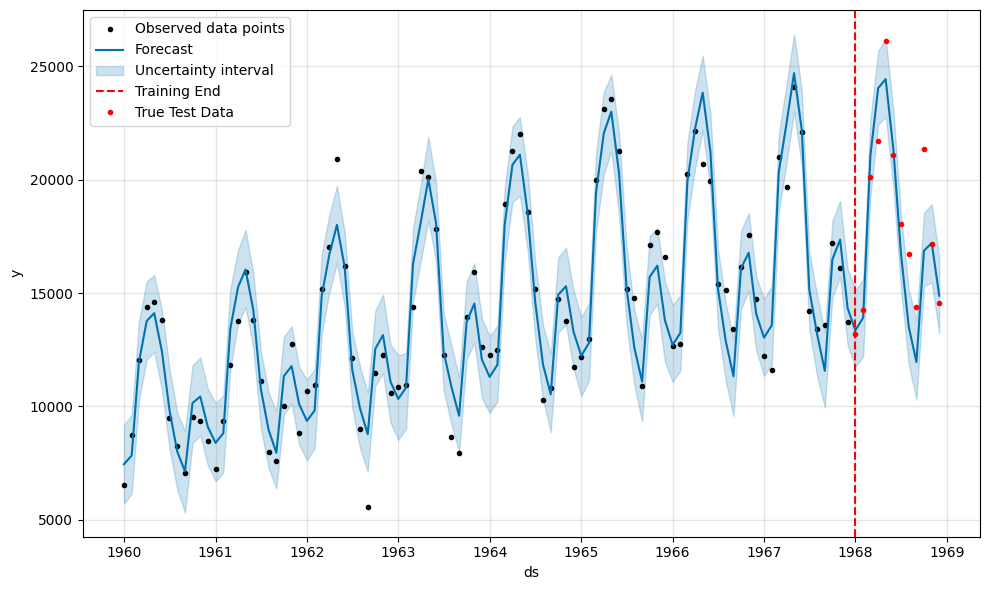

In [9]:
#For plotting the forecast values Prophet has direct methods
forecast_plot = model.plot(fore)
axes = forecast_plot.gca()
axes.axvline(x=fore['ds'].iloc[-12], color='red', linestyle='--', label='Training End')

df_data_test['ds'] = pd.to_datetime(df_data_test['ds'])
plt.plot(df_data_test['ds'], df_data_test['y'],'ro', markersize=3, label='True Test Data')
plt.legend()
plt.show()